# Benchmarks

Avaliações sobre `output/normalized.csv` (pipeline `classifier_api.ipynb`).

| # | Benchmark | Módulo | Saída |
|---|-----------|--------|-------|
| 1 | **Constância** (match exato de `normalized` por `original`) | `benchmark.benchmark` | `output/normalized.json` |
| 2 | **Por tipo de ataque** (`mode_match_rate` por `tipo_variacao`) | `benchmark.by_attack_type` | `output/by_attack_type.json` |
| 3 | **Weighted string distance** (constância com custo ponderado de edição) | `benchmark.weighted_distance` | `output/weighted_string_distance.json` |
| 4 | **Blocking** (clustering por unidade + similaridade) | `benchmark.blocking` | `output/blocking_results.json` |
| 5 | **Pairwise F1-Score** (hard cases com rótulo humano — gerado automaticamente) | `benchmark.ipynb` | `output/hard_cases.csv` |
| 6 | **Labeled Pairs F1-Score** (pares rotulados manualmente) | `benchmark.ipynb` | `output/labeled_pairs_f1.json` |
| 7 | **Constância por grupo** (union-find sobre label=1, consistência do normalizador) | enchmark.ipynb | — |
| 8 | **Baseline TF-IDF** (comparação com similaridade coseno sem LLM) | aseline.ipynb | output/baseline_metrics.json |

**Pré-requisitos:**
- `attack_augmentation.ipynb` → `data/attack.csv`
- `classifier_api.ipynb` (Passos 1-5) → `output/normalized.csv`
- `classifier_api.ipynb` (Passo 6) → `dados/pairs_normalized.csv`
- `baseline.ipynb` → `dados/baseline_predictions.csv`  

> **Nota sobre `normalized`:** a partir da versão atual, a coluna `normalized` em `output/normalized.csv` contém o **nome canônico completo** (`display_name`), não mais o `match_key` parcial. Re-rode `classifier_api.ipynb` para atualizar o arquivo.

## Setup

In [1]:
import sys
import json
from pathlib import Path


def _repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "benchmark" / "benchmark.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Não achei benchmark/. Rode o notebook em qualquer subpasta do "
        "repositório invoice-data-normalizer."
    )


REPO_ROOT = _repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = Path("output")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
NORMALIZED_PATH = "output/normalized.csv"
ATTACK_PATH     = "data/attack.csv"
WEIGHTED_STRING_DISTANCE_JSON = "output/weighted_string_distance.json"
BLOCKING_JSON   = "output/blocking_results.json"
HARD_CASES_CSV  = "output/hard_cases.csv"
PAIRWISE_F1_JSON = "output/pairwise_f1.json"

CONSISTENCY_JSON     = "output/normalized.json"
BY_ATTACK_TYPE_JSON  = "output/by_attack_type.json"

PAIRS_NORMALIZED_CSV  = "dados/pairs_normalized_run2.csv"
LABELED_PAIRS_F1_JSON = "output/labeled_pairs_f1.json"

## 4b. Utilitario -- Bootstrap CI (precision / recall / F1)

Reamostragem com reposicao sobre os *pares* (mantem a correspondencia rotulo-predicao de cada par), usada nas secoes abaixo para reportar IC 95% junto com precision/recall/F1. Com poucos positivos no ground truth (~28-31 em 1200), a margem de erro real do recall e maior que os 5% assumidos no calculo do tamanho de amostra -- por isso o IC importa mais que o ponto estimado sozinho.

In [3]:
import numpy as np

def bootstrap_pairwise_ci(y_true, y_pred, n_resamples=10000, confidence=0.95, seed=42):
    """IC bootstrap (percentil) para precision/recall/F1, reamostrando pares com reposicao."""
    y_true = np.asarray(y_true, dtype=np.int8)
    y_pred = np.asarray(y_pred, dtype=np.int8)
    n = len(y_true)
    if n == 0:
        raise ValueError("y_true vazio")

    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_resamples, n))
    yt, yp = y_true[idx], y_pred[idx]

    tp = ((yt == 1) & (yp == 1)).sum(axis=1)
    fp = ((yt == 0) & (yp == 1)).sum(axis=1)
    fn = ((yt == 1) & (yp == 0)).sum(axis=1)

    pp, ap = tp + fp, tp + fn
    precision = np.where(pp > 0, tp / np.maximum(pp, 1), 0.0)
    recall    = np.where(ap > 0, tp / np.maximum(ap, 1), 0.0)
    denom = precision + recall
    f1 = np.where(denom > 0, 2 * precision * recall / np.maximum(denom, 1e-12), 0.0)

    alpha = 1 - confidence
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)

    def _ci(arr):
        return [round(float(np.percentile(arr, lo)), 4), round(float(np.percentile(arr, hi)), 4)]

    return {
        "precision_ci95": _ci(precision),
        "recall_ci95":    _ci(recall),
        "f1_ci95":        _ci(f1),
        "n_resamples":    n_resamples,
    }


def bootstrap_mean_ci(values, n_resamples=10000, confidence=0.95, seed=42):
    """IC bootstrap (percentil) para a media de uma lista de valores (ex.: constancia por grupo)."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n == 0:
        raise ValueError("values vazio")

    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_resamples, n))
    means = values[idx].mean(axis=1)

    alpha = 1 - confidence
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return [round(float(np.percentile(means, lo)), 4), round(float(np.percentile(means, hi)), 4)]


print("bootstrap_pairwise_ci / bootstrap_mean_ci definidos (n_resamples=10000, IC 95%).")


bootstrap_pairwise_ci / bootstrap_mean_ci definidos (n_resamples=10000, IC 95%).


## 1. Consistency Benchmark

Para cada `original`, mede quantas linhas compartilham o `normalized` dominante (constância = max_count / group_size).

In [4]:
from benchmark.benchmark import run as run_consistency

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

results_json = Path(CONSISTENCY_JSON).resolve()
consistency = run_consistency(input_csv, results_json)

print("=" * 65)
print("  1. CONSISTENCY BENCHMARK")
print("=" * 65)
print("  Métricas agregadas:")
for k, v in consistency["metrics"].items():
    print(f"    {k:<22s} {v:.4f}" if isinstance(v, float) else f"    {k:<22s} {v}")
print()
print("  Melhor grouping:")
print(f"    original:    {consistency['best_grouping']['original']}")
print(f"    constancy:   {consistency['best_grouping']['constancy']:.4f}")
print(f"    dominant:    {consistency['best_grouping']['dominant_normalized']}")
print()
print("  Pior grouping:")
print(f"    original:    {consistency['worst_grouping']['original']}")
print(f"    constancy:   {consistency['worst_grouping']['constancy']:.4f}")
print(f"    dominant:    {consistency['worst_grouping']['dominant_normalized']}")
print()
print(f"  Salvo em: {CONSISTENCY_JSON}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

## 2. Consistency by Attack Type

Cruza `normalized.csv` com `attack.csv` pelo texto `attacked` e reporta, para cada `tipo_variacao`, a taxa em que o `normalized` coincide com o modo do grupo `original`.

Taxa mais baixa ⇒ aquele tipo de perturbação desestabiliza mais o normalizador.

In [ ]:
from benchmark.by_attack_type import compute as compute_by_attack_type, load_csv_dicts

norm_path = Path(NORMALIZED_PATH).resolve()
attack_path = Path(ATTACK_PATH).resolve()

if not norm_path.is_file():
    raise FileNotFoundError(f"CSV não encontrado: {norm_path}")
if not attack_path.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {attack_path}. Execute attack_augmentation.ipynb antes."
    )

by_attack = compute_by_attack_type(
    load_csv_dicts(norm_path),
    load_csv_dicts(attack_path),
)

out_path = Path(BY_ATTACK_TYPE_JSON).resolve()
out_path.write_text(
    json.dumps(by_attack, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("=" * 65)
print("  2. CONSISTENCY BY ATTACK TYPE")
print("=" * 65)
print(
    f"  joined {by_attack['rows_joined']} rows "
    f"({by_attack['rows_unmatched']} unmatched) "
    f"across {by_attack['n_originals']} originals"
)
print()
print(f"  {'tipo_variacao':<24s} {'n':>5s}  {'mode_match_rate':>15s}")
print(f"  {'-' * 24} {'-' * 5}  {'-' * 15}")
for row in by_attack["by_attack_type"]:
    print(
        f"  {row['tipo_variacao']:<24s} {row['n']:>5d}  "
        f"{row['mode_match_rate']:>15.4f}"
    )
print()
print(f"  Salvo em: {BY_ATTACK_TYPE_JSON}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv

## 3. Weighted String Distance Benchmark

Computa constância agrupando por distância de edição ponderada. Letras têm custo baixo, números têm custo muito alto, de modo que trocas de dígitos não agrupam.

In [ ]:
from benchmark.weighted_distance import run_benchmark_with_weighted_distance

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

out_path = Path(WEIGHTED_STRING_DISTANCE_JSON).resolve()
weighted_results = run_benchmark_with_weighted_distance(input_csv, out_path)

print("=" * 65)
print("  3. WEIGHTED STRING DISTANCE BENCHMARK")
print("=" * 65)
print("  Métricas agregadas:")
for k, v in weighted_results["metrics"].items():
    print(f"    {k:<40s} {v:.4f}" if isinstance(v, float) else f"    {k:<40s} {v}")
print()
print(f"  Salvo em: {out_path}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

## 4. Blocking Benchmark

Computa a constância usando bloqueio por incompatibilidade de unidades e similaridade de strings.

In [ ]:
from benchmark.blocking import run_benchmark_with_blocking

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

out_path = Path(BLOCKING_JSON).resolve()
blocking_results = run_benchmark_with_blocking(input_csv, out_path)

print("=" * 65)
print("  4. BLOCKING BENCHMARK")
print("=" * 65)
print("  Métricas agregadas:")
for k, v in blocking_results["metrics"].items():
    print(f"    {k:<30s} {v:.4f}" if isinstance(v, float) else f"    {k:<30s} {v}")
print()
print(f"  Salvo em: {out_path}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

## 5. Pairwise F1-Score Benchmark

Gera uma amostra de pares difíceis e calcula F1 com base na igualdade das normalizações.

In [5]:
from collections import defaultdict
from csv import DictReader, DictWriter
from difflib import SequenceMatcher
from itertools import combinations
import random

random.seed(42)

input_csv = Path(NORMALIZED_PATH).resolve()
if not input_csv.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {input_csv}. Execute classifier_api.ipynb antes."
    )

reader = DictReader(input_csv.open(encoding="utf-8", newline=""))
rows = [
    {k.lstrip("\ufeff"): v for k, v in row.items()}
    for row in reader
]
if not rows:
    raise ValueError("CSV vazio: não há dados para gerar hard cases.")

groups = defaultdict(list)
for row in rows:
    groups[row["original"].strip()].append(row)

positive_candidates = []
for group in groups.values():
    if len(group) < 2:
        continue
    sample = group if len(group) <= 12 else random.sample(group, 12)
    for a, b in combinations(sample, 2):
        score = SequenceMatcher(None, a["attacked"].lower(), b["attacked"].lower()).ratio()
        positive_candidates.append((score, a, b))

positive_candidates.sort(key=lambda item: item[0], reverse=True)
positives = positive_candidates[:25]

original_keys = list(groups.keys())
negative_candidates = []

sampled_originals = random.sample(original_keys, min(len(original_keys), 50))
for orig_a, orig_b in combinations(sampled_originals, 2):
    sample_a = groups[orig_a] if len(groups[orig_a]) <= 8 else random.sample(groups[orig_a], 8)
    sample_b = groups[orig_b] if len(groups[orig_b]) <= 8 else random.sample(groups[orig_b], 8)
    for a in sample_a:
        for b in sample_b:
            score = SequenceMatcher(None, a["attacked"].lower(), b["attacked"].lower()).ratio()
            negative_candidates.append((score, a, b))

negative_candidates.sort(key=lambda item: item[0], reverse=True)
negatives = negative_candidates[:25]

hard_pairs = []
for score, a, b in positives + negatives:
    hard_pairs.append({
        "original_A": a["original"],
        "attacked_A": a["attacked"],
        "normalized_A": a["normalized"],
        "original_B": b["original"],
        "attacked_B": b["attacked"],
        "normalized_B": b["normalized"],
        "label": "1" if a["original"].strip() == b["original"].strip() else "0",
        "attack_similarity": f"{score:.4f}",
    })

output_path = Path(HARD_CASES_CSV).resolve()
output_path.parent.mkdir(parents=True, exist_ok=True)
with output_path.open("w", encoding="utf-8", newline="") as fh:
    writer = DictWriter(
        fh,
        fieldnames=[
            "original_A",
            "attacked_A",
            "normalized_A",
            "original_B",
            "attacked_B",
            "normalized_B",
            "label",
            "attack_similarity",
        ],
    )
    writer.writeheader()
    writer.writerows(hard_pairs)

print(f"Gerado {len(hard_pairs)} pares difíceis em: {output_path}")

FileNotFoundError: CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\normalized.csv. Execute classifier_api.ipynb antes.

In [6]:
from csv import DictReader
from pathlib import Path
import json

hard_path = Path(HARD_CASES_CSV).resolve()
if not hard_path.is_file():
    raise FileNotFoundError(f"Arquivo de hard cases não encontrado: {hard_path}")

pairs = list(DictReader(hard_path.open(encoding="utf-8", newline="")))
if not pairs:
    raise ValueError("Nenhum par encontrado em hard cases.")

true_positives = 0
false_positives = 0
false_negatives = 0
true_negatives = 0
errors = []
for row in pairs:
    label = int(row["label"])
    prediction = row["normalized_A"].strip() == row["normalized_B"].strip()
    if prediction and label == 1:
        true_positives += 1
    elif prediction and label == 0:
        false_positives += 1
        errors.append((row, "FP"))
    elif not prediction and label == 1:
        false_negatives += 1
        errors.append((row, "FN"))
    else:
        true_negatives += 1

precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) else 0.0
recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

metrics = {
    "true_positives": true_positives,
    "false_positives": false_positives,
    "false_negatives": false_negatives,
    "true_negatives": true_negatives,
    "precision": round(precision, 4),
    "recall": round(recall, 4),
    "f1_score": round(f1, 4),
    "num_pairs": len(pairs),
}

print("=" * 65)
print("  5. PAIRWISE F1-SCORE BENCHMARK")
print("=" * 65)
print("  Métricas:")
for k, v in metrics.items():
    print(f"    {k:<20s} {v}")
print()
print(f"  Hard cases lidos de: {hard_path}")

with Path(PAIRWISE_F1_JSON).open("w", encoding="utf-8") as fh:
    json.dump(metrics, fh, ensure_ascii=False, indent=2)

print(f"  Salvo métricas em: {Path(PAIRWISE_F1_JSON).resolve()}")

FileNotFoundError: Arquivo de hard cases não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\hard_cases.csv

## 6. Labeled Pairs F1-Score (`pairs_to_label.csv`)

Lê `dados/pairs_normalized.csv` (gerado por `classifier_api.ipynb` — Passo 6) e calcula F1 com base em `item_a_normalized == item_b_normalized` versus o `label` humano.

- **Predição positiva**: normalizações idênticas → mesmo produto
- **TP**: par é match (label=1) e normalizações são iguais
- **FN**: par é match (label=1) mas normalizações divergem (falso negativo — normalizador inconsistente)
- **FP**: par não é match (label=0) mas normalizações colidiram (falso positivo — normalizador colapsa produtos diferentes)

In [7]:
import re
from csv import DictReader, DictWriter
from difflib import SequenceMatcher

# ── Parâmetros ────────────────────────────────────────────────
SIMILARITY_THRESHOLD = 0.90  # reduzido de 0.90 para capturar mais TPs com variações menores

# Captura dígitos com unidade opcional (64gb, 500ml, 21v, 12kg, 55pol, 4k, etc.)
_NUM_RE = re.compile(
    r"\d+(?:[.,]\d+)?\s?(?:gb|tb|mb|ml|kg|g(?!b)\b|l\b|v\b|w\b|pol|k\b|hz|mhz|ghz|mm|cm|rpm|ah?)\b",
    re.I,
)
# separa dimensoes coladas tipo "10cmx50m" -> "10cm x50m" (senao "cm" nao tem
# fronteira de palavra antes do "x" e o regex acima nao reconhece o numero)
_RE_DIM_X = re.compile(r"([a-zA-Z])x(\d)", re.I)

def _extract_numbers(text: str) -> frozenset:
    """Tokens numéricos com unidade, normalizados (vírgula → ponto, sem espaço)."""
    text = _RE_DIM_X.sub(r"\1 x\2", text)
    return frozenset(m.group().lower().replace(",", ".").replace(" ", "") for m in _NUM_RE.finditer(text))

def _str_sim(a: str, b: str) -> float:
    return SequenceMatcher(None, a.lower().strip(), b.lower().strip()).ratio()

def post_normalize(text: str) -> str:
    """Normaliza o nome canônico antes da comparação, sem alterar o CSV.
    - Remove vírgulas antes de dígitos: 'frontier, 2.5' -> 'frontier 2.5'
    - Normaliza hifens em códigos alfanuméricos: 'sx-2' -> 'sx2'
    """
    text = re.sub(r",\s*(\d)", r" \1", text)
    text = re.sub(r"([a-zA-Z])-(\d)", r"\1\2", text)
    text = re.sub(r"(\d)-([a-zA-Z])", r"\1\2", text)
    text = re.sub(r"\s{2,}", " ", text)
    return text.strip()

def _extract_qtd_number(value: str):
    """Primeiro inteiro num valor de quantidade ("kit 12" -> 12, "3" -> 3)."""
    if not value:
        return None
    m = re.search(r"\d+", str(value))
    return int(m.group()) if m else None


# Bloqueio por "palavra + numero divergente" (ex.: "lamina 10" vs "lamina 15",
# "32 led" vs "30 leds", "3 lugares" vs "2 lugares") -- specs soltas em
# outros_atributos, sem unidade reconhecida por _NUM_RE. So dispara quando a
# MESMA palavra aparece nos dois lados com numero diferente (testado contra
# os pares positivos reais: so afetou o caso "Strada 2010" vs "Strada 2009",
# que e uma divergencia real de especificacao, aceito).
_RE_WORD_THEN_NUM = re.compile(r"\b([a-zà-úçã]{3,})\s+(\d+)\b", re.I)
_RE_NUM_THEN_WORD = re.compile(r"\b(\d+)\s+([a-zà-úçã]{3,})\b", re.I)

def _word_number_pairs(text: str) -> dict:
    pairs = {}
    for w, n in _RE_WORD_THEN_NUM.findall(text):
        pairs[w.lower().rstrip("s")] = n
    for n, w in _RE_NUM_THEN_WORD.findall(text):
        pairs.setdefault(w.lower().rstrip("s"), n)
    return pairs

def _has_word_number_conflict(a: str, b: str) -> bool:
    pa, pb = _word_number_pairs(a), _word_number_pairs(b)
    return any(w in pb and pa[w] != pb[w] for w in pa)


def predict_weighted(norm_a: str, norm_b: str, qtd_a: str = "", qtd_b: str = "") -> tuple[float, int]:
    """
    Etapa 0 — bloqueio por quantidade: se ambos tiverem quantidade extraída e os
        números divergirem, bloqueia direto. Cobre contagens sem unidade
        ("kit 12" vs "20 unidades") que o regex de números-com-unidade da
        Etapa 2 não reconhece (ex.: "aromatizante - 12" vs "- 20" tinha
        similaridade 0.97, passava do threshold; agora bloqueia aqui).
    Etapa 1 — post_normalize: remove vírgulas antes de dígitos e hifens em códigos.
    Etapa 2 — bloqueio por número: bloqueia só se os conjuntos de números CONFLITAM
        (nem um é subconjunto do outro). Permite que uma descrição mais detalhada
        ('1cv 4a') seja comparada com uma mais curta ('1cv') que omite a spec extra.
    Etapa 3 — similaridade de string >= SIMILARITY_THRESHOLD.
    """
    # Ausencia de quantidade == 1 unidade implicita (mesma convencao do
    # _normalize_quantidade no classifier_api). Sem o "or 1", um par "1 vs 15"
    # escapava do bloqueio porque o lado "1" virava None na exibicao.
    n_qtd_a = _extract_qtd_number(qtd_a) or 1
    n_qtd_b = _extract_qtd_number(qtd_b) or 1
    if n_qtd_a != n_qtd_b:
        return 0.0, 0

    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)

    nums_a = _extract_numbers(norm_a_clean)
    nums_b = _extract_numbers(norm_b_clean)
    if nums_a and nums_b and not (nums_a <= nums_b or nums_b <= nums_a):
        return 0.0, 0
    if _has_word_number_conflict(norm_a_clean, norm_b_clean):
        return 0.0, 0
    sim = _str_sim(norm_a_clean, norm_b_clean)
    return round(sim, 4), 1 if sim >= SIMILARITY_THRESHOLD else 0


# ── Carrega CSV e enriquece ───────────────────────────────────
pairs_path = Path(PAIRS_NORMALIZED_CSV).resolve()
if not pairs_path.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {pairs_path}. "
        "Execute classifier_api.ipynb (Passo 6) antes."
    )

with pairs_path.open(encoding="utf-8-sig", newline="") as fh:
    pairs = list(DictReader(fh))

if not pairs:
    raise ValueError("CSV de pares normalizado está vazio.")

for row in pairs:
    norm_a = row["item_a_normalized"].strip()
    norm_b = row["item_b_normalized"].strip()
    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)
    row["exact_match_pred"]  = "1" if norm_a_clean == norm_b_clean else "0"
    sim, wpred               = predict_weighted(norm_a, norm_b, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
    row["string_similarity"] = f"{sim:.4f}"
    row["weighted_pred"]     = str(wpred)

fieldnames = list(pairs[0].keys())
with pairs_path.open("w", encoding="utf-8-sig", newline="") as fh:
    writer = DictWriter(fh, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(pairs)

print(f"CSV enriquecido salvo: {pairs_path}")
print(f"Parâmetros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto\n")

# ── F1 para os dois métodos ───────────────────────────────────
def compute_metrics(pairs, pred_col):
    tp = fp = fn = tn = 0
    for row in pairs:
        label = int(row["label"].strip())
        pred  = int(row[pred_col])
        if   pred == 1 and label == 1: tp += 1
        elif pred == 1 and label == 0: fp += 1
        elif pred == 0 and label == 1: fn += 1
        else:                          tn += 1
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                precision=round(precision, 4), recall=round(recall, 4),
                f1_score=round(f1, 4), num_pairs=len(pairs))

metrics_exact    = compute_metrics(pairs, "exact_match_pred")
metrics_weighted = compute_metrics(pairs, "weighted_pred")

for title, m in [("Exact Match  (post_normalize aplicado)", metrics_exact),
                 (f"Weighted (bloqueio subconjunto + similaridade >= {SIMILARITY_THRESHOLD})", metrics_weighted)]:
    print("=" * 65)
    print(f"  {title}")
    print("=" * 65)
    for k, v in m.items():
        print(f"    {k:<20s} {v}")
    print()

out_path = Path(LABELED_PAIRS_F1_JSON).resolve()
out_path.parent.mkdir(parents=True, exist_ok=True)
with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":        metrics_exact,
        "weighted":           metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Métricas salvas em: {out_path}")

# IC 95% bootstrap (10000 reamostragens sobre os pares) + n_positive/n_negative explicitos
_y_true = [int(row["label"].strip()) for row in pairs]
_y_pred_exact    = [int(row["exact_match_pred"]) for row in pairs]
_y_pred_weighted = [int(row["weighted_pred"])    for row in pairs]

ci_exact    = bootstrap_pairwise_ci(_y_true, _y_pred_exact)
ci_weighted = bootstrap_pairwise_ci(_y_true, _y_pred_weighted)

metrics_exact["n_positive"]    = metrics_exact["tp"] + metrics_exact["fn"]
metrics_exact["n_negative"]    = metrics_exact["fp"] + metrics_exact["tn"]
metrics_weighted["n_positive"] = metrics_weighted["tp"] + metrics_weighted["fn"]
metrics_weighted["n_negative"] = metrics_weighted["fp"] + metrics_weighted["tn"]
metrics_exact.update(ci_exact)
metrics_weighted.update(ci_weighted)

print(f"  IC 95% Exact    -> precision {ci_exact['precision_ci95']}  recall {ci_exact['recall_ci95']}  f1 {ci_exact['f1_ci95']}")
print(f"  IC 95% Weighted -> precision {ci_weighted['precision_ci95']}  recall {ci_weighted['recall_ci95']}  f1 {ci_weighted['f1_ci95']}")
print(f"  n_positive={metrics_exact['n_positive']}  n_negative={metrics_exact['n_negative']}  (n={metrics_exact['num_pairs']})")

with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":         metrics_exact,
        "weighted":            metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Metricas (com IC) re-salvas em: {out_path}")


CSV enriquecido salvo: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_run2.csv
Parâmetros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto

  Exact Match  (post_normalize aplicado)
    tp                   14
    fp                   1
    fn                   16
    tn                   1169
    precision            0.9333
    recall               0.4667
    f1_score             0.6222
    num_pairs            1200

  Weighted (bloqueio subconjunto + similaridade >= 0.9)
    tp                   20
    fp                   1
    fn                   10
    tn                   1169
    precision            0.9524
    recall               0.6667
    f1_score             0.7843
    num_pairs            1200

Métricas salvas em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\labeled_pairs_f1.json
  IC 95% Exact    -> precision [0.7778, 1.0]  recall [0.2857, 0.6522]  f1 [0.4324, 0.7755]
  IC 95% Weighted -> precision [0.84, 1.0]  re

### 6b. Comparação Estruturada (campo a campo)

Em vez de achatar o JSON numa string, compara os campos extraídos individualmente:

| Campo | Lógica |
|---|---|
| `marca`, `modelo`, `capacidade_volume`, `voltagem` | **Bloqueio duro** — se ambos presentes e diferentes → prediz 0 |
| `tipo_produto` | **Soft match** — se similaridade < 0.45 → prediz 0 |
| Sinal positivo | Se ≥1 campo coincide → prediz 1 |
| Fallback | Se todos nulos → usa similaridade da string canônica ≥ 0.75 |

**Pré-requisito:** re-executar o Passo 6 de `classifier_api.ipynb` para gerar as colunas `a_marca`, `a_modelo`, etc. no CSV.

In [8]:
import re
from csv import DictReader, DictWriter
from difflib import SequenceMatcher

# ── Parâmetros ────────────────────────────────────────────────
SIMILARITY_THRESHOLD = 0.90  # alinhado com a celula 13020c99 -- estava divergente em 0.85

# Captura dígitos com unidade opcional (64gb, 500ml, 21v, 12kg, 55pol, 4k, etc.)
_NUM_RE = re.compile(
    r"\d+(?:[.,]\d+)?\s?(?:gb|tb|mb|ml|kg|g(?!b)\b|l\b|v\b|w\b|pol|k\b|hz|mhz|ghz|mm|cm|rpm|ah?)\b",
    re.I,
)
# separa dimensoes coladas tipo "10cmx50m" -> "10cm x50m" (senao "cm" nao tem
# fronteira de palavra antes do "x" e o regex acima nao reconhece o numero)
_RE_DIM_X = re.compile(r"([a-zA-Z])x(\d)", re.I)

def _extract_numbers(text: str) -> frozenset:
    """Tokens numéricos com unidade, normalizados (vírgula → ponto, sem espaço)."""
    text = _RE_DIM_X.sub(r"\1 x\2", text)
    return frozenset(m.group().lower().replace(",", ".").replace(" ", "") for m in _NUM_RE.finditer(text))

def _str_sim(a: str, b: str) -> float:
    return SequenceMatcher(None, a.lower().strip(), b.lower().strip()).ratio()

def post_normalize(text: str) -> str:
    """Normaliza o nome canônico antes da comparação, sem alterar o CSV.
    - Remove vírgulas antes de dígitos: 'frontier, 2.5' -> 'frontier 2.5'
    - Normaliza hifens em códigos alfanuméricos: 'sx-2' -> 'sx2'
    """
    text = re.sub(r",\s*(\d)", r" \1", text)
    text = re.sub(r"([a-zA-Z])-(\d)", r"\1\2", text)
    text = re.sub(r"(\d)-([a-zA-Z])", r"\1\2", text)
    text = re.sub(r"\s{2,}", " ", text)
    return text.strip()

def _extract_qtd_number(value: str):
    """Primeiro inteiro num valor de quantidade ("kit 12" -> 12, "3" -> 3)."""
    if not value:
        return None
    m = re.search(r"\d+", str(value))
    return int(m.group()) if m else None


# Bloqueio por "palavra + numero divergente" (ex.: "lamina 10" vs "lamina 15",
# "32 led" vs "30 leds", "3 lugares" vs "2 lugares") -- specs soltas em
# outros_atributos, sem unidade reconhecida por _NUM_RE. So dispara quando a
# MESMA palavra aparece nos dois lados com numero diferente (testado contra
# os pares positivos reais: so afetou o caso "Strada 2010" vs "Strada 2009",
# que e uma divergencia real de especificacao, aceito).
_RE_WORD_THEN_NUM = re.compile(r"\b([a-zà-úçã]{3,})\s+(\d+)\b", re.I)
_RE_NUM_THEN_WORD = re.compile(r"\b(\d+)\s+([a-zà-úçã]{3,})\b", re.I)

def _word_number_pairs(text: str) -> dict:
    pairs = {}
    for w, n in _RE_WORD_THEN_NUM.findall(text):
        pairs[w.lower().rstrip("s")] = n
    for n, w in _RE_NUM_THEN_WORD.findall(text):
        pairs.setdefault(w.lower().rstrip("s"), n)
    return pairs

def _has_word_number_conflict(a: str, b: str) -> bool:
    pa, pb = _word_number_pairs(a), _word_number_pairs(b)
    return any(w in pb and pa[w] != pb[w] for w in pa)


def predict_weighted(norm_a: str, norm_b: str, qtd_a: str = "", qtd_b: str = "") -> tuple[float, int]:
    """
    Etapa 0 — bloqueio por quantidade: se ambos tiverem quantidade extraída e os
        números divergirem, bloqueia direto. Cobre contagens sem unidade
        ("kit 12" vs "20 unidades") que o regex de números-com-unidade da
        Etapa 2 não reconhece (ex.: "aromatizante - 12" vs "- 20" tinha
        similaridade 0.97, passava do threshold; agora bloqueia aqui).
    Etapa 1 — post_normalize: remove vírgulas antes de dígitos e hifens em códigos.
    Etapa 2 — bloqueio por número: bloqueia só se os conjuntos de números CONFLITAM
        (nem um é subconjunto do outro). Permite que uma descrição mais detalhada
        ('1cv 4a') seja comparada com uma mais curta ('1cv') que omite a spec extra.
    Etapa 3 — similaridade de string >= SIMILARITY_THRESHOLD.
    """
    # Ausencia de quantidade == 1 unidade implicita (mesma convencao do
    # _normalize_quantidade no classifier_api). Sem o "or 1", um par "1 vs 15"
    # escapava do bloqueio porque o lado "1" virava None na exibicao.
    n_qtd_a = _extract_qtd_number(qtd_a) or 1
    n_qtd_b = _extract_qtd_number(qtd_b) or 1
    if n_qtd_a != n_qtd_b:
        return 0.0, 0

    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)

    nums_a = _extract_numbers(norm_a_clean)
    nums_b = _extract_numbers(norm_b_clean)
    if nums_a and nums_b and not (nums_a <= nums_b or nums_b <= nums_a):
        return 0.0, 0
    if _has_word_number_conflict(norm_a_clean, norm_b_clean):
        return 0.0, 0
    sim = _str_sim(norm_a_clean, norm_b_clean)
    return round(sim, 4), 1 if sim >= SIMILARITY_THRESHOLD else 0


# ── Carrega CSV e enriquece ───────────────────────────────────
pairs_path = Path(PAIRS_NORMALIZED_CSV).resolve()
if not pairs_path.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {pairs_path}. "
        "Execute classifier_api.ipynb (Passo 6) antes."
    )

with pairs_path.open(encoding="utf-8-sig", newline="") as fh:
    pairs = list(DictReader(fh))

if not pairs:
    raise ValueError("CSV de pares normalizado está vazio.")

for row in pairs:
    norm_a = row["item_a_normalized"].strip()
    norm_b = row["item_b_normalized"].strip()
    norm_a_clean = post_normalize(norm_a)
    norm_b_clean = post_normalize(norm_b)
    row["exact_match_pred"]  = "1" if norm_a_clean == norm_b_clean else "0"
    sim, wpred               = predict_weighted(norm_a, norm_b, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
    row["string_similarity"] = f"{sim:.4f}"
    row["weighted_pred"]     = str(wpred)

fieldnames = list(pairs[0].keys())
with pairs_path.open("w", encoding="utf-8-sig", newline="") as fh:
    writer = DictWriter(fh, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(pairs)

print(f"CSV enriquecido salvo: {pairs_path}")
print(f"Parâmetros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto\n")

# ── F1 para os dois métodos ───────────────────────────────────
def compute_metrics(pairs, pred_col):
    tp = fp = fn = tn = 0
    for row in pairs:
        label = int(row["label"].strip())
        pred  = int(row[pred_col])
        if   pred == 1 and label == 1: tp += 1
        elif pred == 1 and label == 0: fp += 1
        elif pred == 0 and label == 1: fn += 1
        else:                          tn += 1
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                precision=round(precision, 4), recall=round(recall, 4),
                f1_score=round(f1, 4), num_pairs=len(pairs))

metrics_exact    = compute_metrics(pairs, "exact_match_pred")
metrics_weighted = compute_metrics(pairs, "weighted_pred")

for title, m in [("Exact Match  (post_normalize aplicado)", metrics_exact),
                 (f"Weighted (bloqueio subconjunto + similaridade >= {SIMILARITY_THRESHOLD})", metrics_weighted)]:
    print("=" * 65)
    print(f"  {title}")
    print("=" * 65)
    for k, v in m.items():
        print(f"    {k:<20s} {v}")
    print()

out_path = Path(LABELED_PAIRS_F1_JSON).resolve()
out_path.parent.mkdir(parents=True, exist_ok=True)
with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":        metrics_exact,
        "weighted":           metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Métricas salvas em: {out_path}")

# IC 95% bootstrap (10000 reamostragens sobre os pares) + n_positive/n_negative explicitos
_y_true = [int(row["label"].strip()) for row in pairs]
_y_pred_exact    = [int(row["exact_match_pred"]) for row in pairs]
_y_pred_weighted = [int(row["weighted_pred"])    for row in pairs]

ci_exact    = bootstrap_pairwise_ci(_y_true, _y_pred_exact)
ci_weighted = bootstrap_pairwise_ci(_y_true, _y_pred_weighted)

metrics_exact["n_positive"]    = metrics_exact["tp"] + metrics_exact["fn"]
metrics_exact["n_negative"]    = metrics_exact["fp"] + metrics_exact["tn"]
metrics_weighted["n_positive"] = metrics_weighted["tp"] + metrics_weighted["fn"]
metrics_weighted["n_negative"] = metrics_weighted["fp"] + metrics_weighted["tn"]
metrics_exact.update(ci_exact)
metrics_weighted.update(ci_weighted)

print(f"  IC 95% Exact    -> precision {ci_exact['precision_ci95']}  recall {ci_exact['recall_ci95']}  f1 {ci_exact['f1_ci95']}")
print(f"  IC 95% Weighted -> precision {ci_weighted['precision_ci95']}  recall {ci_weighted['recall_ci95']}  f1 {ci_weighted['f1_ci95']}")
print(f"  n_positive={metrics_exact['n_positive']}  n_negative={metrics_exact['n_negative']}  (n={metrics_exact['num_pairs']})")

with out_path.open("w", encoding="utf-8") as fh:
    json.dump({
        "exact_match":         metrics_exact,
        "weighted":            metrics_weighted,
        "similarity_threshold": SIMILARITY_THRESHOLD,
    }, fh, ensure_ascii=False, indent=2)
print(f"Metricas (com IC) re-salvas em: {out_path}")


CSV enriquecido salvo: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_run2.csv
Parâmetros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto

  Exact Match  (post_normalize aplicado)
    tp                   14
    fp                   1
    fn                   16
    tn                   1169
    precision            0.9333
    recall               0.4667
    f1_score             0.6222
    num_pairs            1200

  Weighted (bloqueio subconjunto + similaridade >= 0.9)
    tp                   20
    fp                   1
    fn                   10
    tn                   1169
    precision            0.9524
    recall               0.6667
    f1_score             0.7843
    num_pairs            1200

Métricas salvas em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\labeled_pairs_f1.json
  IC 95% Exact    -> precision [0.7778, 1.0]  recall [0.2857, 0.6522]  f1 [0.4324, 0.7755]
  IC 95% Weighted -> precision [0.84, 1.0]  re

### 6d. Cerebras gpt-oss-120b (`pairs_normalized_cerebras120b.csv`)

Mesmas métricas da seção 6, aplicadas às normalizações geradas pelo Cerebras gpt-oss-120b. **Não faz parte dos 3 modelos reportados no artigo** (Gemini, GPT-5.4-mini, DeepSeek).  
**Nota:** este arquivo foi gerado por uma versão anterior do classifier_api.ipynb; a célula que o produzia foi reaproveitada para a seção da DeepSeek (Passo 9) e não há mais como regerá-lo a partir do notebook atual. Se o arquivo não existir em `dados/`, esta seção pula.

In [9]:
_csv_cbr  = "dados/pairs_normalized_cerebras120b.csv"
_json_cbr = "output/labeled_pairs_f1_cerebras120b.json"

_path_cbr = Path(_csv_cbr).resolve()
if not _path_cbr.is_file():
    print(f"[SKIP] CSV não encontrado: {_path_cbr}\nExecute classifier_api.ipynb (Passo 9) antes.")
else:
    from csv import DictReader, DictWriter as _DW
    with _path_cbr.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_cbr = list(DictReader(fh))

    for row in _pairs_cbr:
        na = row["item_a_normalized"].strip()
        nb = row["item_b_normalized"].strip()
        row["exact_match_pred"]  = "1" if post_normalize(na) == post_normalize(nb) else "0"
        sim, wpred               = predict_weighted(na, nb, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
        row["string_similarity"] = f"{sim:.4f}"
        row["weighted_pred"]     = str(wpred)

    with _path_cbr.open("w", encoding="utf-8-sig", newline="") as fh:
        w = _DW(fh, fieldnames=list(_pairs_cbr[0].keys()))
        w.writeheader(); w.writerows(_pairs_cbr)

    _m_exact_cbr    = compute_metrics(_pairs_cbr, "exact_match_pred")
    _m_weighted_cbr = compute_metrics(_pairs_cbr, "weighted_pred")

    for title, m in [("Exact Match", _m_exact_cbr),
                     (f"Weighted (bloqueio subconjunto + sim >= {SIMILARITY_THRESHOLD})", _m_weighted_cbr)]:
        print("=" * 65)
        print(f"  {title}")
        print("=" * 65)
        for k, v in m.items():
            print(f"    {k:<20s} {v}")
        print()

    with Path(_json_cbr).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_cbr, "weighted": _m_weighted_cbr,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Métricas salvas em: {Path(_json_cbr).resolve()}")

    # IC 95% bootstrap + n_positive/n_negative explicitos
    _y_true_cbr = [int(row["label"].strip()) for row in _pairs_cbr]
    _y_pred_exact_cbr    = [int(row["exact_match_pred"]) for row in _pairs_cbr]
    _y_pred_weighted_cbr = [int(row["weighted_pred"])    for row in _pairs_cbr]

    _ci_exact_cbr    = bootstrap_pairwise_ci(_y_true_cbr, _y_pred_exact_cbr)
    _ci_weighted_cbr = bootstrap_pairwise_ci(_y_true_cbr, _y_pred_weighted_cbr)

    _m_exact_cbr["n_positive"]    = _m_exact_cbr["tp"] + _m_exact_cbr["fn"]
    _m_exact_cbr["n_negative"]    = _m_exact_cbr["fp"] + _m_exact_cbr["tn"]
    _m_weighted_cbr["n_positive"] = _m_weighted_cbr["tp"] + _m_weighted_cbr["fn"]
    _m_weighted_cbr["n_negative"] = _m_weighted_cbr["fp"] + _m_weighted_cbr["tn"]
    _m_exact_cbr.update(_ci_exact_cbr)
    _m_weighted_cbr.update(_ci_weighted_cbr)

    print(f"  IC 95% Exact    -> precision {_ci_exact_cbr['precision_ci95']}  recall {_ci_exact_cbr['recall_ci95']}  f1 {_ci_exact_cbr['f1_ci95']}")
    print(f"  IC 95% Weighted -> precision {_ci_weighted_cbr['precision_ci95']}  recall {_ci_weighted_cbr['recall_ci95']}  f1 {_ci_weighted_cbr['f1_ci95']}")

    with Path(_json_cbr).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_cbr, "weighted": _m_weighted_cbr,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Metricas (com IC) re-salvas em: {Path(_json_cbr).resolve()}")


[SKIP] CSV não encontrado: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_cerebras120b.csv
Execute classifier_api.ipynb (Passo 9) antes.


### 6e. GPT-5.4 mini — OpenAI (`pairs_normalized_openai_gpt5.4mini.csv`)

Mesmas métricas da seção 6, aplicadas às normalizações geradas pelo GPT-5.4 mini via OpenAI.

In [10]:
_csv_gpt  = "dados/pairs_normalized_openai_gpt5.4mini.csv"
_json_gpt = "output/labeled_pairs_f1_gpt5.4mini.json"

_path_gpt = Path(_csv_gpt).resolve()
if not _path_gpt.is_file():
    print(f"[SKIP] CSV não encontrado: {_path_gpt}")
else:
    from csv import DictReader, DictWriter as _DW
    with _path_gpt.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_gpt = list(DictReader(fh))

    for row in _pairs_gpt:
        na = row["item_a_normalized"].strip()
        nb = row["item_b_normalized"].strip()
        row["exact_match_pred"]  = "1" if post_normalize(na) == post_normalize(nb) else "0"
        sim, wpred               = predict_weighted(na, nb, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
        row["string_similarity"] = f"{sim:.4f}"
        row["weighted_pred"]     = str(wpred)

    with _path_gpt.open("w", encoding="utf-8-sig", newline="") as fh:
        w = _DW(fh, fieldnames=list(_pairs_gpt[0].keys()))
        w.writeheader(); w.writerows(_pairs_gpt)

    _m_exact_gpt    = compute_metrics(_pairs_gpt, "exact_match_pred")
    _m_weighted_gpt = compute_metrics(_pairs_gpt, "weighted_pred")

    print(f"Parametros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)\n")
    for title, m in [("Exact Match (post_normalize aplicado)", _m_exact_gpt),
                     (f"Weighted (bloqueio subconjunto + sim >= {SIMILARITY_THRESHOLD})", _m_weighted_gpt)]:
        print("=" * 65)
        print(f"  {title}")
        print("=" * 65)
        for k, v in m.items():
            print(f"    {k:<20s} {v}")
        print()

    with Path(_json_gpt).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_gpt, "weighted": _m_weighted_gpt,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Métricas salvas em: {Path(_json_gpt).resolve()}")

    # IC 95% bootstrap + n_positive/n_negative explicitos
    _y_true_gpt = [int(row["label"].strip()) for row in _pairs_gpt]
    _y_pred_exact_gpt    = [int(row["exact_match_pred"]) for row in _pairs_gpt]
    _y_pred_weighted_gpt = [int(row["weighted_pred"])    for row in _pairs_gpt]

    _ci_exact_gpt    = bootstrap_pairwise_ci(_y_true_gpt, _y_pred_exact_gpt)
    _ci_weighted_gpt = bootstrap_pairwise_ci(_y_true_gpt, _y_pred_weighted_gpt)

    _m_exact_gpt["n_positive"]    = _m_exact_gpt["tp"] + _m_exact_gpt["fn"]
    _m_exact_gpt["n_negative"]    = _m_exact_gpt["fp"] + _m_exact_gpt["tn"]
    _m_weighted_gpt["n_positive"] = _m_weighted_gpt["tp"] + _m_weighted_gpt["fn"]
    _m_weighted_gpt["n_negative"] = _m_weighted_gpt["fp"] + _m_weighted_gpt["tn"]
    _m_exact_gpt.update(_ci_exact_gpt)
    _m_weighted_gpt.update(_ci_weighted_gpt)

    print(f"  IC 95% Exact    -> precision {_ci_exact_gpt['precision_ci95']}  recall {_ci_exact_gpt['recall_ci95']}  f1 {_ci_exact_gpt['f1_ci95']}")
    print(f"  IC 95% Weighted -> precision {_ci_weighted_gpt['precision_ci95']}  recall {_ci_weighted_gpt['recall_ci95']}  f1 {_ci_weighted_gpt['f1_ci95']}")

    with Path(_json_gpt).open("w", encoding="utf-8") as fh:
        json.dump({"exact_match": _m_exact_gpt, "weighted": _m_weighted_gpt,
                   "similarity_threshold": SIMILARITY_THRESHOLD}, fh, ensure_ascii=False, indent=2)
    print(f"Metricas (com IC) re-salvas em: {Path(_json_gpt).resolve()}")


Parametros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)

  Exact Match (post_normalize aplicado)
    tp                   10
    fp                   8
    fn                   20
    tn                   1162
    precision            0.5556
    recall               0.3333
    f1_score             0.4167
    num_pairs            1200

  Weighted (bloqueio subconjunto + sim >= 0.9)
    tp                   13
    fp                   15
    fn                   17
    tn                   1155
    precision            0.4643
    recall               0.4333
    f1_score             0.4483
    num_pairs            1200

Métricas salvas em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\labeled_pairs_f1_gpt5.4mini.json
  IC 95% Exact    -> precision [0.3077, 0.7895]  recall [0.1667, 0.5152]  f1 [0.2222, 0.5854]
  IC 95% Weighted -> precision [0.2727, 0.6538]  recall [0.2581, 0.6154]  f1 [0.2745, 0.6]
Metricas (com IC) re-salva

### 6f. DeepSeek V4 Flash (`pairs_normalized_deepseek.csv`)

Mesma avaliação de F1 para o **DeepSeek V4 Flash** (modo não-pensante, `extra_body={"thinking":{"type":"disabled"}}`).
Reutiliza `compute_metrics`, `post_normalize` e `predict_weighted` definidos na seção 6.

In [11]:
_csv_ds  = "dados/pairs_normalized_deepseek.csv"
_json_ds = "output/labeled_pairs_f1_deepseek.json"
_path_ds = Path(_csv_ds).resolve()

if not _path_ds.is_file():
    print(f"[SKIP] CSV não encontrado: {_path_ds}")
else:
    from csv import DictReader as _DR_ds, DictWriter as _DW_ds
    with _path_ds.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_ds = list(_DR_ds(fh))

    for row in _pairs_ds:
        na = row["item_a_normalized"].strip()
        nb = row["item_b_normalized"].strip()
        row["exact_match_pred"]  = "1" if post_normalize(na) == post_normalize(nb) else "0"
        sim, wpred               = predict_weighted(na, nb, row.get("a_quantidade", ""), row.get("b_quantidade", ""))
        row["string_similarity"] = f"{sim:.4f}"
        row["weighted_pred"]     = str(wpred)

    with _path_ds.open("w", encoding="utf-8-sig", newline="") as fh:
        w = _DW_ds(fh, fieldnames=list(_pairs_ds[0].keys()))
        w.writeheader(); w.writerows(_pairs_ds)

    _m_exact_ds    = compute_metrics(_pairs_ds, "exact_match_pred")
    _m_weighted_ds = compute_metrics(_pairs_ds, "weighted_pred")

    print(f"Parametros: threshold={SIMILARITY_THRESHOLD} | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)\n")
    for _label, _m in [("Exact Match (post_normalize aplicado)", _m_exact_ds), (f"Weighted (bloqueio subconjunto + sim >= {SIMILARITY_THRESHOLD})", _m_weighted_ds)]:
        print("=" * 65)
        print(f"  {_label}")
        print("=" * 65)
        for k, v in _m.items():
            print(f"    {k:<24s} {v}")

    import json as _jmod
    Path("output").mkdir(exist_ok=True)
    with Path(_json_ds).open("w", encoding="utf-8") as fh:
        _jmod.dump({"exact_match": _m_exact_ds, "weighted": _m_weighted_ds,
                    "similarity_threshold": SIMILARITY_THRESHOLD},
                   fh, ensure_ascii=False, indent=2)
    print(f"\nSalvo: {_json_ds}")

    # IC 95% bootstrap + n_positive/n_negative explicitos
    _y_true_ds = [int(row["label"].strip()) for row in _pairs_ds]
    _y_pred_exact_ds    = [int(row["exact_match_pred"]) for row in _pairs_ds]
    _y_pred_weighted_ds = [int(row["weighted_pred"])    for row in _pairs_ds]

    _ci_exact_ds    = bootstrap_pairwise_ci(_y_true_ds, _y_pred_exact_ds)
    _ci_weighted_ds = bootstrap_pairwise_ci(_y_true_ds, _y_pred_weighted_ds)

    _m_exact_ds["n_positive"]    = _m_exact_ds["tp"] + _m_exact_ds["fn"]
    _m_exact_ds["n_negative"]    = _m_exact_ds["fp"] + _m_exact_ds["tn"]
    _m_weighted_ds["n_positive"] = _m_weighted_ds["tp"] + _m_weighted_ds["fn"]
    _m_weighted_ds["n_negative"] = _m_weighted_ds["fp"] + _m_weighted_ds["tn"]
    _m_exact_ds.update(_ci_exact_ds)
    _m_weighted_ds.update(_ci_weighted_ds)

    print(f"  IC 95% Exact    -> precision {_ci_exact_ds['precision_ci95']}  recall {_ci_exact_ds['recall_ci95']}  f1 {_ci_exact_ds['f1_ci95']}")
    print(f"  IC 95% Weighted -> precision {_ci_weighted_ds['precision_ci95']}  recall {_ci_weighted_ds['recall_ci95']}  f1 {_ci_weighted_ds['f1_ci95']}")

    with Path(_json_ds).open("w", encoding="utf-8") as fh:
        _jmod.dump({"exact_match": _m_exact_ds, "weighted": _m_weighted_ds,
                    "similarity_threshold": SIMILARITY_THRESHOLD},
                   fh, ensure_ascii=False, indent=2)
    print(f"Metricas (com IC) re-salvas em: {_json_ds}")


Parametros: threshold=0.9 | post_normalize=ON | bloqueio=subconjunto (mesma predict_weighted do Gemini)

  Exact Match (post_normalize aplicado)
    tp                       13
    fp                       21
    fn                       17
    tn                       1149
    precision                0.3824
    recall                   0.4333
    f1_score                 0.4062
    num_pairs                1200
  Weighted (bloqueio subconjunto + sim >= 0.9)
    tp                       16
    fp                       26
    fn                       14
    tn                       1144
    precision                0.381
    recall                   0.5333
    f1_score                 0.4444
    num_pairs                1200

Salvo: output/labeled_pairs_f1_deepseek.json
  IC 95% Exact    -> precision [0.2195, 0.55]  recall [0.2593, 0.6176]  f1 [0.2456, 0.5495]
  IC 95% Weighted -> precision [0.2333, 0.5319]  recall [0.3478, 0.7097]  f1 [0.2903, 0.579]
Metricas (com IC) re-salvas em: ou

## Matriz de Confusão — Labeled Pairs

Comparação visual dos dois métodos de predição sobre os 1200 pares rotulados.

In [12]:
def print_confusion_matrix(m: dict, title: str) -> None:
    tp, fp, fn, tn = m["tp"], m["fp"], m["fn"], m["tn"]
    total = tp + fp + fn + tn
    w = 14

    print(f"\n{'─' * 58}")
    print(f"  {title}")
    print(f"{'─' * 58}")
    print(f"  {'':>{w}}  {'Pred MATCH':>{w}}  {'Pred NO-MATCH':>{w}}")
    print(f"  {'─' * (w * 3 + 6)}")
    print(f"  {'Real MATCH':>{w}}  {f'TP = {tp}':>{w}}  {f'FN = {fn}':>{w}}")
    print(f"  {'Real NO-MATCH':>{w}}  {f'FP = {fp}':>{w}}  {f'TN = {tn}':>{w}}")
    print(f"  {'─' * (w * 3 + 6)}")
    print(f"  Precision : {m['precision']:.4f}   Recall : {m['recall']:.4f}   F1 : {m['f1_score']:.4f}")
    print(f"  Accuracy  : {(tp + tn) / total:.4f}  ({tp + tn}/{total} corretos)")

print_confusion_matrix(metrics_exact,    "Exact Match  (item_a_normalized == item_b_normalized)")
print_confusion_matrix(metrics_weighted, f"Weighted  (bloqueio por número + similaridade ≥ {SIMILARITY_THRESHOLD})")

print()
print("  FN = matches reais com normalizações divergentes  → inconsistência do LLM")
print("  FP = não-matches com normalização colapsada       → normalização genérica demais")


──────────────────────────────────────────────────────────
  Exact Match  (item_a_normalized == item_b_normalized)
──────────────────────────────────────────────────────────
                      Pred MATCH   Pred NO-MATCH
  ────────────────────────────────────────────────
      Real MATCH         TP = 14         FN = 16
   Real NO-MATCH          FP = 1       TN = 1169
  ────────────────────────────────────────────────
  Precision : 0.9333   Recall : 0.4667   F1 : 0.6222
  Accuracy  : 0.9858  (1183/1200 corretos)

──────────────────────────────────────────────────────────
  Weighted  (bloqueio por número + similaridade ≥ 0.9)
──────────────────────────────────────────────────────────
                      Pred MATCH   Pred NO-MATCH
  ────────────────────────────────────────────────
      Real MATCH         TP = 20         FN = 10
   Real NO-MATCH          FP = 1       TN = 1169
  ────────────────────────────────────────────────
  Precision : 0.9524   Recall : 0.6667   F1 : 0.7843
  Ac

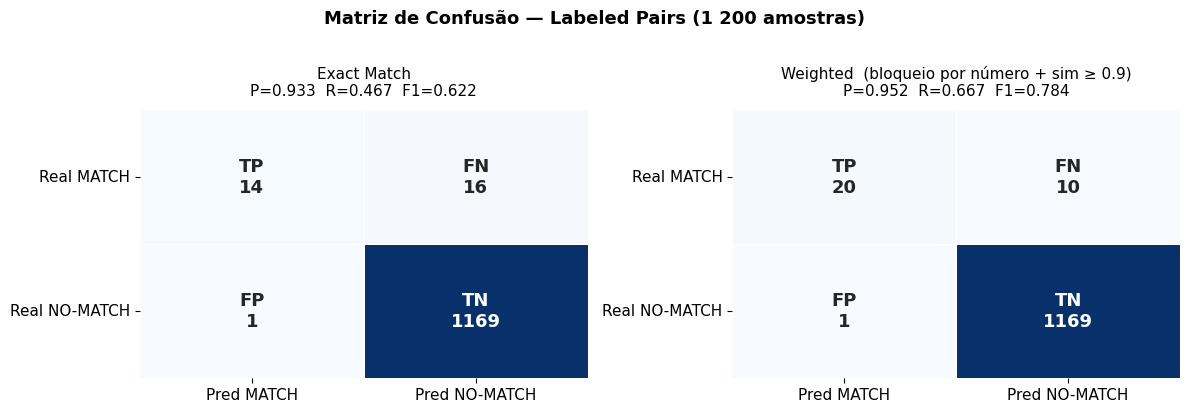

Salvo em: output/confusion_matrix.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

def plot_confusion_matrix(m: dict, title: str, ax: plt.Axes) -> None:
    matrix = np.array([[m["tp"], m["fn"]],
                        [m["fp"], m["tn"]]])
    labels = np.array([
        [f"TP\n{m['tp']}", f"FN\n{m['fn']}"],
        [f"FP\n{m['fp']}", f"TN\n{m['tn']}"],
    ])

    sns.heatmap(
        matrix,
        annot=labels,
        fmt="",
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        cbar=False,
        ax=ax,
        annot_kws={"size": 13, "weight": "bold"},
    )
    ax.set_xticklabels(["Pred MATCH", "Pred NO-MATCH"], fontsize=11)
    ax.set_yticklabels(["Real MATCH", "Real NO-MATCH"], fontsize=11, rotation=0)
    ax.set_title(
        f"{title}\nP={m['precision']:.3f}  R={m['recall']:.3f}  F1={m['f1_score']:.3f}",
        fontsize=11, pad=10,
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Matriz de Confusão — Labeled Pairs (1 200 amostras)", fontsize=13, fontweight="bold", y=1.02)

plot_confusion_matrix(metrics_exact,    "Exact Match", axes[0])
plot_confusion_matrix(metrics_weighted, f"Weighted  (bloqueio por número + sim ≥ {SIMILARITY_THRESHOLD})", axes[1])

plt.tight_layout()
plt.savefig("output/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Salvo em: output/confusion_matrix.png")

In [14]:
import pandas as pd

# Carregar os pares enriquecidos
df = pd.read_csv("dados/pairs_normalized.csv")
df['label'] = df['label'].astype(int)
df['exact_match_pred'] = df['exact_match_pred'].astype(int)

# Filtro de Falsos Negativos (Atrapalham o Recall)
# Itens são iguais, mas a normalização gerou strings diferentes
fn_df = df[(df['label'] == 1) & (df['exact_match_pred'] == 0)]

# Filtro de Falsos Positivos (Atrapalham a Precision)
# Itens são diferentes, mas a normalização os tornou idênticos
fp_df = df[(df['label'] == 0) & (df['exact_match_pred'] == 1)]

colunas_interesse = ['item_a_normalized', 'item_b_normalized'] 

print(f"--- FALSOS POSITIVOS: {len(fp_df)} (Deixou genérico demais) ---")
display(fp_df[colunas_interesse].head(10))

print(f"\n--- FALSOS NEGATIVOS: {len(fn_df)} (Inconsistente na formatação) ---")
display(fn_df[colunas_interesse].head(10))

--- FALSOS POSITIVOS: 1 (Deixou genérico demais) ---


,item_a_normalized,item_b_normalized
1163,estetoscópio Littmann classic iii,estetoscópio Littmann classic iii



--- FALSOS NEGATIVOS: 16 (Inconsistente na formatação) ---


,item_a_normalized,item_b_normalized
50,grama erva gato - 6,sementes grama erva gatos - 6
80,sementes grama erva gatos - 3,grama erva gato - 6
148,"cartão memória Sandisk ultra, classe 10 - 64 gb","cartão memória Sandisk ultra, micro sd xc - 64 gb"
341,"carburador cht, gasolina","carburador cht 1.6, gasolina"
353,iluminador luz estúdio - 2,iluminador estúdio - 2
533,faixa adesiva - 5 cm,faixa adesiva máquina tatoo - 5 cm
627,esparadrapo Missner 10cm x 50mt,esparadrapo Missner 10cm x 50m
674,"controle longa distancia Stetsom sx-2, 500 metros","controle longa distancia Stetsom amarelo sx2, ..."
707,top biquíni cropped com bojo,top biquíni com bojo
765,lâmina trator Husqvarna lt 1597 - 2,"lâmina faca Husqvarna lt131 lt1597, 18538 - 2"


## 7. Constância das Normalizações (grupos do mesmo produto)

Para cada grupo de títulos que representam o **mesmo produto** (pares com `label=1` unidos transitivamente via union-find), calcula a constância das normalizações usando distância de edição ponderada — letras têm custo baixo, dígitos têm custo alto, impedindo que quantidades diferentes sejam agrupadas.

- **Constância exata**: fração do grupo que gerou a string normalizada dominante idêntica
- **Constância ponderada**: fração do grupo no cluster dominante por distância ponderada (tolera typos/abreviações, rejeita trocas de dígito)

In [15]:
from collections import Counter, defaultdict
from benchmark.weighted_distance import constancy_with_weighted_distance

# ── Reconstrói mapeamento título → normalização ───────────────
title_to_norm: dict[str, str] = {}
for row in pairs:
    title_to_norm[row["title_a"].strip()] = row["item_a_normalized"].strip()
    title_to_norm[row["title_b"].strip()] = row["item_b_normalized"].strip()

# ── Union-Find sobre pares label=1 ────────────────────────────
parent: dict[str, str] = {}

def _find(x: str) -> str:
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent.setdefault(parent[x], parent[x])
        x = parent[x]
    return x

def _union(a: str, b: str) -> None:
    pa, pb = _find(a), _find(b)
    if pa != pb:
        parent[pa] = pb

for row in pairs:
    if row["label"].strip() == "1":
        _union(row["title_a"].strip(), row["title_b"].strip())

# ── Agrupa normalizações por produto ──────────────────────────
groups_norm: dict[str, list[str]] = defaultdict(list)
for title, norm in title_to_norm.items():
    if title in parent:
        groups_norm[_find(title)].append(norm)

# ── Calcula constância por grupo ──────────────────────────────
group_results = []
for root, norms in groups_norm.items():
    if len(norms) < 2:
        continue
    counter = Counter(norms)
    exact_dom = max(counter.values())
    constancy_exact = exact_dom / len(norms)

    constancy_wd, _, dom_wd, _ = constancy_with_weighted_distance(norms)

    group_results.append({
        "group_size":        len(norms),
        "constancy_exact":   round(constancy_exact, 4),
        "constancy_weighted": round(constancy_wd, 4),
        "dominant_norm":     counter.most_common(1)[0][0],
        "all_norms":         norms,
    })

group_results.sort(key=lambda r: r["constancy_exact"])

# ── Métricas agregadas ────────────────────────────────────────
if group_results:
    mean_exact    = sum(r["constancy_exact"]    for r in group_results) / len(group_results)
    mean_weighted = sum(r["constancy_weighted"] for r in group_results) / len(group_results)
    n_perfect_exact    = sum(1 for r in group_results if r["constancy_exact"]    == 1.0)
    n_perfect_weighted = sum(1 for r in group_results if r["constancy_weighted"] == 1.0)
else:
    mean_exact = mean_weighted = 0.0
    n_perfect_exact = n_perfect_weighted = 0

print("=" * 65)
print("  7. CONSTÂNCIA POR GRUPO DE PRODUTO")
print("=" * 65)
print(f"  Grupos avaliados (≥2 títulos): {len(group_results)}")
print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
print(f"  {'─' * 35} {'─' * 8}  {'─' * 9}")
print(f"  {'Constância média':<35s} {mean_exact:>8.4f}  {mean_weighted:>9.4f}")
print(f"  {'Grupos com constância = 1.0':<35s} {n_perfect_exact:>8d}  {n_perfect_weighted:>9d}")
print(f"  {'Total de grupos':<35s} {len(group_results):>8d}")
print()

if group_results:
    print("  Grupos com menor constância exata:")
    for r in group_results[:5]:
        print(f"    constância exata={r['constancy_exact']:.2f}  ponderada={r['constancy_weighted']:.2f}  (n={r['group_size']})")
        for n in r["all_norms"]:
            print(f"      · {n}")
        print()

# Distribuicao de tamanho dos grupos + IC 95% da constancia media
from collections import Counter as _Counter30
group_size_distribution = dict(sorted(_Counter30(r["group_size"] for r in group_results).items()))

if group_results:
    ci_mean_exact    = bootstrap_mean_ci([r["constancy_exact"]    for r in group_results])
    ci_mean_weighted = bootstrap_mean_ci([r["constancy_weighted"] for r in group_results])
else:
    ci_mean_exact = ci_mean_weighted = [None, None]

print("  Distribuicao de tamanho dos grupos (group_size -> numero de grupos):")
for size, count in group_size_distribution.items():
    print(f"    {size:>3d} titulos : {count} grupo(s)")
print()
print(f"  IC 95% constancia media exata    : {ci_mean_exact}")
print(f"  IC 95% constancia media ponderada: {ci_mean_weighted}")

CONSTANCY_GROUPS_JSON = Path("output/constancy_groups.json")
with CONSTANCY_GROUPS_JSON.open("w", encoding="utf-8") as fh:
    json.dump({
        "n_groups":                     len(group_results),
        "mean_constancy_exact":         round(mean_exact, 4) if group_results else None,
        "mean_constancy_exact_ci95":    ci_mean_exact,
        "mean_constancy_weighted":      round(mean_weighted, 4) if group_results else None,
        "mean_constancy_weighted_ci95": ci_mean_weighted,
        "group_size_distribution":      group_size_distribution,
        "groups":                       group_results,
    }, fh, ensure_ascii=False, indent=2)
print(f"\nSalvo em: {CONSTANCY_GROUPS_JSON.resolve()}")


  7. CONSTÂNCIA POR GRUPO DE PRODUTO
  Grupos avaliados (≥2 títulos): 26
  Métrica                                Exata  Ponderada
  ─────────────────────────────────── ────────  ─────────
  Constância média                      0.6795     0.8718
  Grupos com constância = 1.0                9         19
  Total de grupos                           26

  Grupos com menor constância exata:
    constância exata=0.50  ponderada=1.00  (n=2)
      · grama erva gato - 6
      · sementes grama erva gatos - 6

    constância exata=0.50  ponderada=0.50  (n=2)
      · cartão memória Sandisk ultra, classe 10 - 64 gb
      · cartão memória Sandisk ultra, micro sd xc - 64 gb

    constância exata=0.50  ponderada=1.00  (n=2)
      · controle longa distancia Stetsom amarelo sx2, 500m
      · controle longa distancia Stetsom sx-2, 500 metros

    constância exata=0.50  ponderada=0.50  (n=2)
      · porta toalha Deca 2040.c.flx, barra
      · porta toalha Deca 2040 c37, izy

    constância exata=0.50  po

### 7b. Constância — OpenAI gpt-5.4-mini

Mesma análise de constância por grupo usando `dados/pairs_normalized_openai_gpt5.4mini.csv`.  
Reutiliza o union-find de `label=1` já construído na seção 7.

In [28]:
_csv_7b = "dados/pairs_normalized_openai_gpt5.4mini.csv"
_path_7b = Path(_csv_7b).resolve()
if not _path_7b.is_file():
    _csv_7b = "dados/pairs_normalized_openai_gpt4omini.csv"
    _path_7b = Path(_csv_7b).resolve()

if not _path_7b.is_file():
    print(f"[SKIP] nenhum CSV gpt4omini/gpt5.4mini encontrado em dados/")
else:
    from csv import DictReader as _DR7b
    from collections import defaultdict as _dd7b, Counter as _Cnt7b
    with _path_7b.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_7b = list(_DR7b(fh))

    _t2n_7b = {}
    for row in _pairs_7b:
        _t2n_7b[row["title_a"].strip()] = row["item_a_normalized"].strip()
        _t2n_7b[row["title_b"].strip()] = row["item_b_normalized"].strip()

    _gn_7b = _dd7b(list)
    for title, norm in _t2n_7b.items():
        if title in parent:
            _gn_7b[_find(title)].append(norm)

    _res_7b = []
    for root, norms in _gn_7b.items():
        if len(norms) < 2: continue
        cnt = _Cnt7b(norms)
        ce = max(cnt.values()) / len(norms)
        cw, _, _, _ = constancy_with_weighted_distance(norms)
        _res_7b.append({"group_size": len(norms), "constancy_exact": round(ce,4),
                        "constancy_weighted": round(cw,4), "all_norms": norms})
    _res_7b.sort(key=lambda r: r["constancy_exact"])

    if _res_7b:
        _me = sum(r["constancy_exact"]    for r in _res_7b) / len(_res_7b)
        _mw = sum(r["constancy_weighted"] for r in _res_7b) / len(_res_7b)
        _pe = sum(1 for r in _res_7b if r["constancy_exact"]    == 1.0)
        _pw = sum(1 for r in _res_7b if r["constancy_weighted"] == 1.0)
    else:
        _me = _mw = 0.0; _pe = _pw = 0

    _model_label = "gpt-5.4-mini" if "gpt5.4" in _csv_7b else "gpt-4o-mini"
    print("=" * 65)
    print(f"  7b. CONSTÂNCIA — OpenAI {_model_label}")
    print("=" * 65)
    print(f"  Grupos avaliados (≥2 títulos): {len(_res_7b)}")
    print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
    print(f"  {'─'*35} {'─'*8}  {'─'*9}")
    print(f"  {'Constância média':<35s} {_me:>8.4f}  {_mw:>9.4f}")
    print(f"  {'Grupos com constância = 1.0':<35s} {_pe:>8d}  {_pw:>9d}")
    print(f"  {'Total de grupos':<35s} {len(_res_7b):>8d}")
    if _res_7b:
        print("\n  Grupos com menor constância exata:")
        for r in _res_7b[:5]:
            print(f"    exata={r['constancy_exact']:.2f}  pond={r['constancy_weighted']:.2f}  (n={r['group_size']})")
            for n in r["all_norms"]: print(f"      · {n}")

    _gsd_7b = dict(sorted(_Cnt7b(r["group_size"] for r in _res_7b).items()))
    if _res_7b:
        _ci_me_7b = bootstrap_mean_ci([r["constancy_exact"]    for r in _res_7b])
        _ci_mw_7b = bootstrap_mean_ci([r["constancy_weighted"] for r in _res_7b])
    else:
        _ci_me_7b = _ci_mw_7b = [None, None]
    print(f"\n  IC 95% constancia media exata    : {_ci_me_7b}")
    print(f"  IC 95% constancia media ponderada: {_ci_mw_7b}")

    _CONSTANCY_JSON_7b = Path("output/constancy_groups_gpt.json")
    with _CONSTANCY_JSON_7b.open("w", encoding="utf-8") as fh:
        json.dump({
            "n_groups":                     len(_res_7b),
            "mean_constancy_exact":         round(_me, 4) if _res_7b else None,
            "mean_constancy_exact_ci95":    _ci_me_7b,
            "mean_constancy_weighted":      round(_mw, 4) if _res_7b else None,
            "mean_constancy_weighted_ci95": _ci_mw_7b,
            "group_size_distribution":      _gsd_7b,
            "groups":                       _res_7b,
        }, fh, ensure_ascii=False, indent=2)
    print(f"  Salvo em: {_CONSTANCY_JSON_7b.resolve()}")

  7b. CONSTÂNCIA — OpenAI gpt-5.4-mini
  Grupos avaliados (≥2 títulos): 26
  Métrica                                Exata  Ponderada
  ─────────────────────────────────── ────────  ─────────
  Constância média                      0.6282     0.8269
  Grupos com constância = 1.0                6         17
  Total de grupos                           26

  Grupos com menor constância exata:
    exata=0.50  pond=1.00  (n=2)
      · grama gato - kit 3
      · sementes - kit 3
    exata=0.50  pond=0.50  (n=2)
      · cartao memoria Sandisk ultra, classe 10 - 64 gb
      · cartão memória Sandisk micro sd xc - 64 gb
    exata=0.50  pond=1.00  (n=2)
      · balde pipoca Personali - 30
      · balde pipoca Personali - kit 30
    exata=0.50  pond=1.00  (n=2)
      · controle Stetsom amarelo sx2 - 500 ml
      · controle Stetsom sx-2, 500 metros
    exata=0.50  pond=0.50  (n=2)
      · porta toalha Deca 2040.c.flx
      · porta toalha Deca izy 2040 c37

  IC 95% constancia media exata    : [0.551

### 7c. Constância — Cerebras gpt-oss-120b

Mesma análise de constância por grupo usando `dados/pairs_normalized_cerebras120b.csv`.  
Reutiliza o union-find de `label=1` já construído na seção 7.

In [17]:
_csv_7c = "dados/pairs_normalized_cerebras120b.csv"
_path_7c = Path(_csv_7c).resolve()

if not _path_7c.is_file():
    print(f"[SKIP] {_path_7c} não encontrado.")
else:
    from csv import DictReader as _DR7c
    from collections import defaultdict as _dd7c, Counter as _Cnt7c
    with _path_7c.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_7c = list(_DR7c(fh))

    _t2n_7c = {}
    for row in _pairs_7c:
        _t2n_7c[row["title_a"].strip()] = row["item_a_normalized"].strip()
        _t2n_7c[row["title_b"].strip()] = row["item_b_normalized"].strip()

    _gn_7c = _dd7c(list)
    for title, norm in _t2n_7c.items():
        if title in parent:
            _gn_7c[_find(title)].append(norm)

    _res_7c = []
    for root, norms in _gn_7c.items():
        if len(norms) < 2: continue
        cnt = _Cnt7c(norms)
        ce = max(cnt.values()) / len(norms)
        cw, _, _, _ = constancy_with_weighted_distance(norms)
        _res_7c.append({"group_size": len(norms), "constancy_exact": round(ce,4),
                        "constancy_weighted": round(cw,4), "all_norms": norms})
    _res_7c.sort(key=lambda r: r["constancy_exact"])

    if _res_7c:
        _me = sum(r["constancy_exact"]    for r in _res_7c) / len(_res_7c)
        _mw = sum(r["constancy_weighted"] for r in _res_7c) / len(_res_7c)
        _pe = sum(1 for r in _res_7c if r["constancy_exact"]    == 1.0)
        _pw = sum(1 for r in _res_7c if r["constancy_weighted"] == 1.0)
    else:
        _me = _mw = 0.0; _pe = _pw = 0

    print("=" * 65)
    print("  7c. CONSTÂNCIA — Cerebras gpt-oss-120b")
    print("=" * 65)
    print(f"  Grupos avaliados (≥2 títulos): {len(_res_7c)}")
    print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
    print(f"  {'─'*35} {'─'*8}  {'─'*9}")
    print(f"  {'Constância média':<35s} {_me:>8.4f}  {_mw:>9.4f}")
    print(f"  {'Grupos com constância = 1.0':<35s} {_pe:>8d}  {_pw:>9d}")
    print(f"  {'Total de grupos':<35s} {len(_res_7c):>8d}")
    if _res_7c:
        print("\n  Grupos com menor constância exata:")
        for r in _res_7c[:5]:
            print(f"    exata={r['constancy_exact']:.2f}  pond={r['constancy_weighted']:.2f}  (n={r['group_size']})")
            for n in r["all_norms"]: print(f"      · {n}")

[SKIP] C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\pairs_normalized_cerebras120b.csv não encontrado.


### 7d. Constância — DeepSeek V4 Flash

Mesma análise de constância por grupo usando `dados/pairs_normalized_deepseek.csv`.
Reutiliza o union-find de `label=1` já construído na seção 7.

In [29]:
_csv_7d = "dados/pairs_normalized_deepseek.csv"
_path_7d = Path(_csv_7d).resolve()

if not _path_7d.is_file():
    print(f"[SKIP] {_path_7d} não encontrado.")
else:
    from csv import DictReader as _DR7d
    from collections import defaultdict as _dd7d, Counter as _Cnt7d
    with _path_7d.open(encoding="utf-8-sig", newline="") as fh:
        _pairs_7d = list(_DR7d(fh))

    _t2n_7d = {}
    for row in _pairs_7d:
        _t2n_7d[row["title_a"].strip()] = row["item_a_normalized"].strip()
        _t2n_7d[row["title_b"].strip()] = row["item_b_normalized"].strip()

    _gn_7d = _dd7d(list)
    for title, norm in _t2n_7d.items():
        if title in parent:
            _gn_7d[_find(title)].append(norm)

    _res_7d = []
    for root, norms in _gn_7d.items():
        if len(norms) < 2: continue
        cnt = _Cnt7d(norms)
        ce = max(cnt.values()) / len(norms)
        cw, _, _, _ = constancy_with_weighted_distance(norms)
        _res_7d.append({"group_size": len(norms), "constancy_exact": round(ce, 4),
                        "constancy_weighted": round(cw, 4), "all_norms": norms})
    _res_7d.sort(key=lambda r: r["constancy_exact"])

    if _res_7d:
        _me = sum(r["constancy_exact"]    for r in _res_7d) / len(_res_7d)
        _mw = sum(r["constancy_weighted"] for r in _res_7d) / len(_res_7d)
        _pe = sum(1 for r in _res_7d if r["constancy_exact"]    == 1.0)
        _pw = sum(1 for r in _res_7d if r["constancy_weighted"] == 1.0)
    else:
        _me = _mw = 0.0; _pe = _pw = 0

    print("=" * 65)
    print("  7d. CONSTÂNCIA — DeepSeek V4 Flash")
    print("=" * 65)
    print(f"  Grupos avaliados (>=2 títulos): {len(_res_7d)}")
    print(f"  {'Métrica':<35s} {'Exata':>8s}  {'Ponderada':>9s}")
    print(f"  {'─'*35} {'─'*8}  {'─'*9}")
    print(f"  {'Constância média':<35s} {_me:>8.4f}  {_mw:>9.4f}")
    print(f"  {'Grupos com constância = 1.0':<35s} {_pe:>8d}  {_pw:>9d}")
    print(f"  {'Total de grupos':<35s} {len(_res_7d):>8d}")
    if _res_7d:
        print("\n  Grupos com menor constância exata:")
        for r in _res_7d[:5]:
            print(f"    exata={r['constancy_exact']:.2f}  pond={r['constancy_weighted']:.2f}  (n={r['group_size']})")
            for n in r["all_norms"]: print(f"      · {n}")

    _gsd_7d = dict(sorted(_Cnt7d(r["group_size"] for r in _res_7d).items()))
    if _res_7d:
        _ci_me_7d = bootstrap_mean_ci([r["constancy_exact"]    for r in _res_7d])
        _ci_mw_7d = bootstrap_mean_ci([r["constancy_weighted"] for r in _res_7d])
    else:
        _ci_me_7d = _ci_mw_7d = [None, None]
    print(f"\n  IC 95% constancia media exata    : {_ci_me_7d}")
    print(f"  IC 95% constancia media ponderada: {_ci_mw_7d}")

    _CONSTANCY_JSON_7d = Path("output/constancy_groups_deepseek.json")
    with _CONSTANCY_JSON_7d.open("w", encoding="utf-8") as fh:
        json.dump({
            "n_groups":                     len(_res_7d),
            "mean_constancy_exact":         round(_me, 4) if _res_7d else None,
            "mean_constancy_exact_ci95":    _ci_me_7d,
            "mean_constancy_weighted":      round(_mw, 4) if _res_7d else None,
            "mean_constancy_weighted_ci95": _ci_mw_7d,
            "group_size_distribution":      _gsd_7d,
            "groups":                       _res_7d,
        }, fh, ensure_ascii=False, indent=2)
    print(f"  Salvo em: {_CONSTANCY_JSON_7d.resolve()}")

  7d. CONSTÂNCIA — DeepSeek V4 Flash
  Grupos avaliados (>=2 títulos): 26
  Métrica                                Exata  Ponderada
  ─────────────────────────────────── ────────  ─────────
  Constância média                      0.6859     0.8846
  Grupos com constância = 1.0                9         20
  Total de grupos                           26

  Grupos com menor constância exata:
    exata=0.50  pond=1.00  (n=2)
      · grama erva gato - 3
      · sementes grama erva gatos - 3
    exata=0.50  pond=0.50  (n=2)
      · cartão memória Sandisk classe 10 - 64 gb
      · cartão memória Sandisk full hd - 64 gb
    exata=0.50  pond=1.00  (n=2)
      · controle Stetsom amarelo sx2, 500m
      · controle Stetsom sx-2, 500 metros
    exata=0.50  pond=0.50  (n=2)
      · porta toalha Deca 2040.c.flx
      · porta toalha Deca izy 2040 c37
    exata=0.50  pond=1.00  (n=2)
      · esfregão
      · vassoura esfregão

  IC 95% constancia media exata    : [0.5962, 0.7756]
  IC 95% constancia med

## 8. Comparação com Baseline — TF-IDF

Carrega dados/baseline_predictions.csv gerado por aseline.ipynb e compara os baselines TF-IDF com o pipeline LLM (seções 6 e 7).

**Pré-requisito:** executar aseline.ipynb antes desta seção.

| Método | Precision | Recall | F1 |
|---|---|---|---|
| TF-IDF word (threshold ótimo) | — | — | — |
| TF-IDF char (threshold ótimo) | — | — | — |
| LLM Exact Match | 0.6667 | 0.4516 | 0.5385 |
| LLM Weighted | 0.5556 | 0.4839 | 0.5172 |

In [27]:
import json
import pandas as pd
from pathlib import Path

BASELINE_CSV  = "dados/baseline_predictions.csv"
BASELINE_JSON = "output/baseline_metrics.json"

baseline_path = Path(BASELINE_CSV).resolve()
if not baseline_path.is_file():
    raise FileNotFoundError(
        f"CSV nao encontrado: {baseline_path}.\n"
        "Execute baseline.ipynb antes desta secao."
    )

df_bl = pd.read_csv(baseline_path, dtype=str, encoding="utf-8-sig")
df_bl["label"] = df_bl["label"].astype(int)

metrics_json = Path(BASELINE_JSON)
if metrics_json.is_file():
    bl_metrics = json.loads(metrics_json.read_text(encoding="utf-8"))
else:
    bl_metrics = {}

def compute_from_df(df, pred_col):
    df[pred_col] = df[pred_col].astype(int)
    tp = int(((df[pred_col] == 1) & (df["label"] == 1)).sum())
    fp = int(((df[pred_col] == 1) & (df["label"] == 0)).sum())
    fn = int(((df[pred_col] == 0) & (df["label"] == 1)).sum())
    tn = int(((df[pred_col] == 0) & (df["label"] == 0)).sum())
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                precision=round(prec,4), recall=round(rec,4), f1_score=round(f1,4),
                n_positive=tp + fn, n_negative=fp + tn, num_pairs=len(df))

m_word = compute_from_df(df_bl, "pred_tfidf_word")
m_char = compute_from_df(df_bl, "pred_tfidf_char")

# IC 95% bootstrap (colunas ja convertidas para int por compute_from_df acima)
ci_word = bootstrap_pairwise_ci(df_bl["label"].tolist(), df_bl["pred_tfidf_word"].tolist())
ci_char = bootstrap_pairwise_ci(df_bl["label"].tolist(), df_bl["pred_tfidf_char"].tolist())
m_word.update(ci_word)
m_char.update(ci_char)

bl_metrics["tfidf_word_optimal"] = {**bl_metrics.get("tfidf_word_optimal", {}), **m_word}
bl_metrics["tfidf_char_optimal"] = {**bl_metrics.get("tfidf_char_optimal", {}), **m_char}
with metrics_json.open("w", encoding="utf-8") as fh:
    json.dump(bl_metrics, fh, ensure_ascii=False, indent=2)

# Metricas do LLM principal (secao 6, Gemini 3.1 Flash-Lite) lidas do resultado
# ja calculado em memoria -- antes estava hardcoded com valores desatualizados
# (0.6667/0.4516), divergentes do que a secao 6 realmente calculava.
m_llm_exact    = metrics_exact
m_llm_weighted = metrics_weighted

thr_word = bl_metrics.get('tfidf_word_optimal', {}).get('threshold', '?')
thr_char = bl_metrics.get('tfidf_char_optimal', {}).get('threshold', '?')

print('=' * 68)
print('  8. COMPARACAO COM BASELINES TF-IDF')
print('=' * 68)
print(f"  {'Metodo':<38s} {'Prec':>6s} {'Rec':>6s} {'F1':>6s}")
print(f"  {'-' * 38} {'-' * 6} {'-' * 6} {'-' * 6}")
print(f"  {f'TF-IDF word  (thr={thr_word})':<38s} {m_word['precision']:>6.4f} {m_word['recall']:>6.4f} {m_word['f1_score']:>6.4f}")
print(f"  {f'TF-IDF char  (thr={thr_char})':<38s} {m_char['precision']:>6.4f} {m_char['recall']:>6.4f} {m_char['f1_score']:>6.4f}")
print(f"  {'Gemini 3.1 Flash-Lite (Exact)':<38s} {m_llm_exact['precision']:>6.4f} {m_llm_exact['recall']:>6.4f} {m_llm_exact['f1_score']:>6.4f}")
print(f"  {'Gemini 3.1 Flash-Lite (Weighted)':<38s} {m_llm_weighted['precision']:>6.4f} {m_llm_weighted['recall']:>6.4f} {m_llm_weighted['f1_score']:>6.4f}")
print()
print(f"  IC 95% TF-IDF word  -> precision {ci_word['precision_ci95']}  recall {ci_word['recall_ci95']}  f1 {ci_word['f1_ci95']}")
print(f"  IC 95% TF-IDF char  -> precision {ci_char['precision_ci95']}  recall {ci_char['recall_ci95']}  f1 {ci_char['f1_ci95']}")

  8. COMPARACAO COM BASELINES TF-IDF
  Metodo                                   Prec    Rec     F1
  -------------------------------------- ------ ------ ------
  TF-IDF word  (thr=0.608)               0.5405 0.6667 0.5970
  TF-IDF char  (thr=0.7789)              0.5135 0.6333 0.5672
  Gemini 3.1 Flash-Lite (Exact)          0.9333 0.4667 0.6222
  Gemini 3.1 Flash-Lite (Weighted)       0.9524 0.6667 0.7843

  IC 95% TF-IDF word  -> precision [0.3721, 0.7]  recall [0.4839, 0.8333]  f1 [0.4444, 0.7246]
  IC 95% TF-IDF char  -> precision [0.35, 0.675]  recall [0.4516, 0.8]  f1 [0.4082, 0.6984]


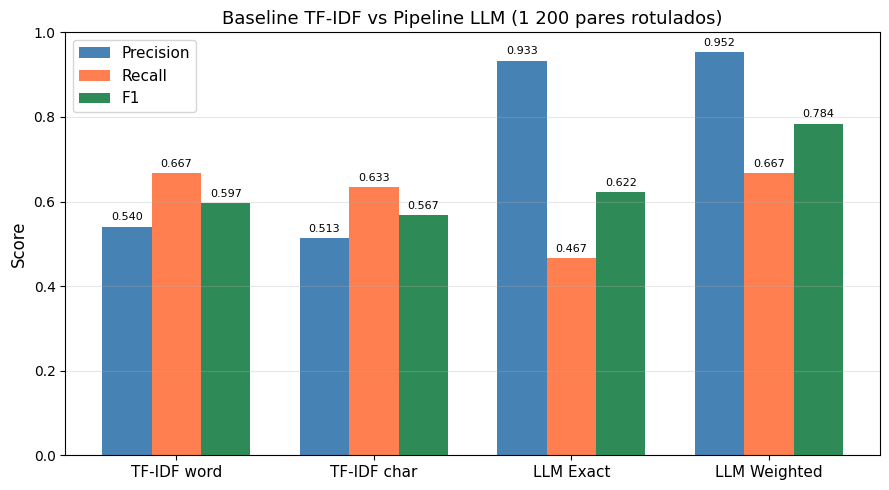

Salvo em: output/baseline_vs_llm.png


In [26]:
import matplotlib.pyplot as plt
import numpy as np

methods  = ['TF-IDF word', 'TF-IDF char', 'LLM Exact', 'LLM Weighted']
precs    = [m_word['precision'], m_char['precision'], m_llm_exact['precision'], m_llm_weighted['precision']]
recs     = [m_word['recall'],    m_char['recall'],    m_llm_exact['recall'],    m_llm_weighted['recall']]
f1s      = [m_word['f1_score'],  m_char['f1_score'],  m_llm_exact['f1_score'],  m_llm_weighted['f1_score']]

x = np.arange(len(methods))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
bars_p = ax.bar(x - width, precs, width, label='Precision', color='steelblue')
bars_r = ax.bar(x,         recs,  width, label='Recall',    color='coral')
bars_f = ax.bar(x + width, f1s,   width, label='F1',        color='seagreen')

ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=11)
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Baseline TF-IDF vs Pipeline LLM (1 200 pares rotulados)', fontsize=13)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

for bar in [*bars_p, *bars_r, *bars_f]:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f'{h:.3f}',
            ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('output/baseline_vs_llm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Salvo em: output/baseline_vs_llm.png')

## 9. Estabilidade entre execuções (não-determinismo do modelo)

Fonte de incerteza **diferente** da IC bootstrap da Seção 6 (aquela mede incerteza de amostragem sobre os 1.200 pares fixos; esta mede o quanto a própria extração do LLM muda entre execuções repetidas do mesmo modelo/prompt/dataset, com `temperature=0`). As duas **não devem ser somadas** — são reportadas separadamente.

Requer rodar `classifier_api.ipynb` mais de uma vez por modelo com `RUN_ID=2,3,4,5` (ver célula de configuração), sem sobrescrever os arquivos canônicos (`RUN_ID=1`, sem sufixo, é o que a Tabela 3 já usa). Recomendação: piloto com `RUN_ID=2` só no Gemini primeiro — se a estabilidade de extração vier ≥0,99, o efeito é pequeno e as demais execuções servem só de confirmação barata; se vier ≤0,90, vale investigar antes de rodar os outros 3 modelos.

Duas métricas, calculadas por modelo a partir de todas as execuções encontradas:
1. **Variação das métricas finais** (precision/recall/F1, exact e weighted): média e desvio-padrão entre execuções.
2. **Estabilidade de extração**: fração de títulos únicos cujo `item_*_normalized` (nome canônico) é *idêntico* em todas as execuções encontradas — isola o efeito antes do limiar de matching, análogo à constância da Seção 7, mas entre execuções em vez de entre grupo de produto.

In [21]:
import glob
import json
import numpy as np
import pandas as pd
import re as _re_stab
from collections import defaultdict
from pathlib import Path

def _find_run_files(pattern: str) -> dict[int, str]:
    """{run_id: caminho}, incluindo run 1 (arquivo canonico sem sufixo _run{k})."""
    runs = {}
    canonical = pattern.format(suffix="")
    if Path(canonical).is_file():
        runs[1] = canonical
    for p in glob.glob(pattern.format(suffix="_run*")):
        m = _re_stab.search(r"_run(\d+)\.csv$", p)
        if m:
            runs[int(m.group(1))] = p
    return dict(sorted(runs.items()))


MODEL_RUN_PATTERNS = {
    "Gemini 3.1 Flash-Lite": "dados/pairs_normalized{suffix}.csv",
    "GPT-5.4-mini":          "dados/pairs_normalized_openai_gpt5.4mini{suffix}.csv",
    "DeepSeek V4 Flash":     "dados/pairs_normalized_deepseek{suffix}.csv",
}

RUN_STABILITY_JSON = Path("output/run_stability.json")


def analyze_model_stability(model_name: str) -> dict | None:
    """Roda a analise de estabilidade pra UM modelo, imprime o relatorio no
    mesmo formato de sempre, e salva/atualiza so a entrada desse modelo em
    output/run_stability.json (preserva o que ja tiver sido salvo pros outros).
    """
    pattern = MODEL_RUN_PATTERNS[model_name]
    runs = _find_run_files(pattern)
    print("=" * 65)
    print(f"  {model_name} -- {len(runs)} execucao(oes) encontrada(s): {list(runs.keys())}")
    print("=" * 65)
    if len(runs) < 2:
        print("  Menos de 2 execucoes -> pulado. Rode classifier_api.ipynb com")
        print("  RUN_ID=2 (piloto) ou 2..5 (completo) para habilitar esta secao.\n")
        return None

    dfs = {}
    for run_id, path in runs.items():
        df = pd.read_csv(path, dtype=str, encoding="utf-8-sig")
        df["item_a_normalized"] = df["item_a_normalized"].fillna("")
        df["item_b_normalized"] = df["item_b_normalized"].fillna("")
        if "a_quantidade" not in df.columns:
            df["a_quantidade"] = ""
        if "b_quantidade" not in df.columns:
            df["b_quantidade"] = ""
        df["a_quantidade"] = df["a_quantidade"].fillna("")
        df["b_quantidade"] = df["b_quantidade"].fillna("")
        df["exact_match_pred"] = [
            "1" if post_normalize(a) == post_normalize(b) else "0"
            for a, b in zip(df["item_a_normalized"], df["item_b_normalized"])
        ]
        df["weighted_pred"] = [
            str(predict_weighted(a, b, qa, qb)[1])
            for a, b, qa, qb in zip(df["item_a_normalized"], df["item_b_normalized"],
                                     df["a_quantidade"], df["b_quantidade"])
        ]
        dfs[run_id] = df

    per_run = []
    for run_id, df in dfs.items():
        records = df.to_dict("records")
        per_run.append({
            "run": run_id,
            "exact": compute_metrics(records, "exact_match_pred"),
            "weighted": compute_metrics(records, "weighted_pred"),
        })

    variation_summary = {}
    for variant in ["exact", "weighted"]:
        prec = [r[variant]["precision"] for r in per_run]
        rec  = [r[variant]["recall"]    for r in per_run]
        f1   = [r[variant]["f1_score"]  for r in per_run]
        variation_summary[variant] = {
            "precision_mean": round(float(np.mean(prec)), 4), "precision_std": round(float(np.std(prec, ddof=1)), 4),
            "recall_mean":    round(float(np.mean(rec)),  4), "recall_std":    round(float(np.std(rec,  ddof=1)), 4),
            "f1_mean":        round(float(np.mean(f1)),   4), "f1_std":        round(float(np.std(f1,   ddof=1)), 4),
            "per_run_values": {"precision": prec, "recall": rec, "f1": f1},
        }
        v = variation_summary[variant]
        print(f"  [{variant:8s}] precision: media={v['precision_mean']:.4f} dp={v['precision_std']:.4f}  valores={prec}")
        print(f"  [{variant:8s}] recall:    media={v['recall_mean']:.4f} dp={v['recall_std']:.4f}  valores={rec}")
        print(f"  [{variant:8s}] f1:        media={v['f1_mean']:.4f} dp={v['f1_std']:.4f}  valores={f1}")
        print()

    title_to_norms = defaultdict(set)
    for run_id, df in dfs.items():
        for col_title, col_norm in [("title_a", "item_a_normalized"), ("title_b", "item_b_normalized")]:
            for t, n in zip(df[col_title], df[col_norm]):
                title_to_norms[t.strip()].add(n.strip())

    n_titles  = len(title_to_norms)
    n_stable  = sum(1 for norms in title_to_norms.values() if len(norms) == 1)
    stab_rate = n_stable / n_titles if n_titles else 0.0
    print(f"  Estabilidade de extracao: {n_stable}/{n_titles} titulos unicos ({stab_rate:.4f}) "
          f"com normalizado identico nas {len(runs)} execucoes")

    unstable_examples = [
        {"title": t, "normalizacoes": sorted(norms)}
        for t, norms in title_to_norms.items() if len(norms) > 1
    ][:5]
    if unstable_examples:
        print("\n  Exemplos de titulos instaveis:")
        for ex in unstable_examples:
            print(f"    {ex['title']!r}")
            for n in ex["normalizacoes"]:
                print(f"      -> {n!r}")
    print()

    result = {
        "runs": list(runs.keys()),
        "metrics_variation": variation_summary,
        "extraction_stability_rate": round(stab_rate, 4),
        "n_titles_unique": n_titles,
        "n_titles_stable": n_stable,
        "unstable_examples": unstable_examples,
    }

    all_results = {}
    if RUN_STABILITY_JSON.is_file():
        all_results = json.loads(RUN_STABILITY_JSON.read_text(encoding="utf-8"))
    all_results[model_name] = result
    RUN_STABILITY_JSON.write_text(json.dumps(all_results, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Salvo em: {RUN_STABILITY_JSON.resolve()}")

    return result


In [22]:
_ = analyze_model_stability("Gemini 3.1 Flash-Lite")


  Gemini 3.1 Flash-Lite -- 3 execucao(oes) encontrada(s): [1, 2, 3]
  [exact   ] precision: media=0.9333 dp=0.0000  valores=[0.9333, 0.9333, 0.9333]
  [exact   ] recall:    media=0.4667 dp=0.0000  valores=[0.4667, 0.4667, 0.4667]
  [exact   ] f1:        media=0.6222 dp=0.0000  valores=[0.6222, 0.6222, 0.6222]

  [weighted] precision: media=0.9524 dp=0.0000  valores=[0.9524, 0.9524, 0.9524]
  [weighted] recall:    media=0.6667 dp=0.0000  valores=[0.6667, 0.6667, 0.6667]
  [weighted] f1:        media=0.7843 dp=0.0000  valores=[0.7843, 0.7843, 0.7843]

  Estabilidade de extracao: 2267/2267 titulos unicos (1.0000) com normalizado identico nas 3 execucoes

Salvo em: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\run_stability.json


In [23]:
_ = analyze_model_stability("GPT-5.4-mini")


  GPT-5.4-mini -- 3 execucao(oes) encontrada(s): [1, 2, 3]
  [exact   ] precision: media=0.5850 dp=0.0279  valores=[0.5556, 0.6111, 0.5882]
  [exact   ] recall:    media=0.3444 dp=0.0193  valores=[0.3333, 0.3667, 0.3333]
  [exact   ] f1:        media=0.4335 dp=0.0219  valores=[0.4167, 0.4583, 0.4255]

  [weighted] precision: media=0.5020 dp=0.0387  valores=[0.4643, 0.5417, 0.5]
  [weighted] recall:    media=0.4222 dp=0.0192  valores=[0.4333, 0.4333, 0.4]
  [weighted] f1:        media=0.4581 dp=0.0204  valores=[0.4483, 0.4815, 0.4444]

  Estabilidade de extracao: 1190/2267 titulos unicos (0.5249) com normalizado identico nas 3 execucoes

  Exemplos de titulos instaveis:
    'Pulseira Casio Original Prata Gshock Dw5600e'
      -> 'pulseira Casio prata dw5600e'
      -> 'pulseira Casio prata dw5600e, gshock'
    'Trimpot 3386f De 500k Uma Volta Lote Com 25 Peças'
      -> 'trimpot 3386f - 25 500000 ml'
      -> 'trimpot 3386f, 500k - 25'
      -> 'trimpot 3386f, uma volta - 25 500 k'
    

In [24]:
_ = analyze_model_stability("DeepSeek V4 Flash")


  DeepSeek V4 Flash -- 3 execucao(oes) encontrada(s): [1, 2, 3]
  [exact   ] precision: media=0.4174 dp=0.0310  valores=[0.3824, 0.4412, 0.4286]
  [exact   ] recall:    media=0.4778 dp=0.0385  valores=[0.4333, 0.5, 0.5]
  [exact   ] f1:        media=0.4455 dp=0.0342  valores=[0.4062, 0.4688, 0.4615]

  [weighted] precision: media=0.4312 dp=0.0468  valores=[0.381, 0.4737, 0.439]
  [weighted] recall:    media=0.5778 dp=0.0385  valores=[0.5333, 0.6, 0.6]
  [weighted] f1:        media=0.4936 dp=0.0441  valores=[0.4444, 0.5294, 0.507]

  Estabilidade de extracao: 1638/2267 titulos unicos (0.7225) com normalizado identico nas 3 execucoes

  Exemplos de titulos instaveis:
    'Pulseira Casio Original Prata Gshock Dw5600e'
      -> 'pulseira Casio prata dw5600e'
      -> 'relógio Casio prata dw5600e'
    'Cadeirinha Reclinável Preta Maestro Bebê 0 À 25 Kg Multikids'
      -> 'cadeirinha Multikids preta maestro - 25 kg'
      -> 'cadeirinha Multikids preta maestro, 25kg'
    'Discos Pastilhas S